In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
customers = pd.read_csv("Dataset/customers.csv")
customers.head()

,customer_id,signup_date,age,gender,city,state,acquisition_channel
0,100001,2024-03-30,18,Female,Nashik,Maharashtra,Paid Search
1,100002,2025-10-18,38,Male,Noida,Uttar Pradesh,Referral
2,100003,2025-03-16,18,Female,Chennai,Tamil Nadu,Organic Search
3,100004,2025-03-10,31,Male,Warangal,Telangana,Social Media
4,100005,2026-05-11,20,Male,Amritsar,Punjab,Organic Search


In [3]:
customers.shape

(20000, 7)

In [4]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   customer_id          20000 non-null  int64
 1   signup_date          20000 non-null  str  
 2   age                  20000 non-null  int64
 3   gender               20000 non-null  str  
 4   city                 20000 non-null  str  
 5   state                20000 non-null  str  
 6   acquisition_channel  20000 non-null  str  
dtypes: int64(2), str(5)
memory usage: 1.1 MB


In [5]:
customers.isnull().sum()

customer_id            0
signup_date            0
age                    0
gender                 0
city                   0
state                  0
acquisition_channel    0
dtype: int64

In [6]:
customers.duplicated().sum()

0

In [7]:
customers["signup_date"] = pd.to_datetime(customers["signup_date"])
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   customer_id          20000 non-null  int64         
 1   signup_date          20000 non-null  datetime64[us]
 2   age                  20000 non-null  int64         
 3   gender               20000 non-null  str           
 4   city                 20000 non-null  str           
 5   state                20000 non-null  str           
 6   acquisition_channel  20000 non-null  str           
dtypes: datetime64[us](1), int64(2), str(4)
memory usage: 1.1 MB


In [8]:
customers.describe()

,customer_id,signup_date,age
count,20000.000000,20000,20000.000000
mean,110000.500000,2025-05-12 13:32:00.960000,31.182950
min,100001.000000,2024-01-01 00:00:00,18.000000
25%,105000.750000,2024-09-04 00:00:00,25.000000
50%,110000.500000,2025-05-13 00:00:00,31.000000
75%,115000.250000,2026-01-17 00:00:00,37.000000
max,120000.000000,2026-09-29 00:00:00,65.000000
std,5773.647028,NaN,8.408937


In [9]:
customers["age"].value_counts()

age
18    1680
31     937
30     898
32     884
29     852
35     834
28     828
27     819
33     816
34     797
26     795
36     753
25     731
24     690
37     654
38     629
40     600
39     594
23     569
22     526
21     476
41     446
20     431
42     411
19     383
43     353
44     312
45     271
46     189
47     167
48     153
49     142
50     102
51      76
52      53
53      43
54      33
55      23
56      13
57       9
59       7
58       7
65       5
60       3
62       2
64       2
61       2
Name: count, dtype: int64

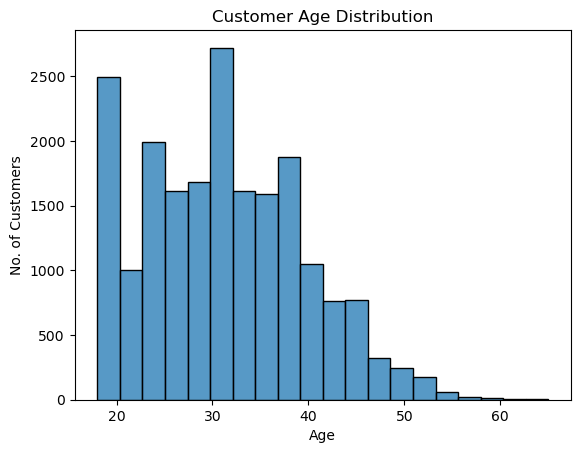

In [10]:
plt.Figure(figsize=(10,5))
sns.histplot(data=customers,x="age", bins=20)
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("No. of Customers")
plt.show()

In [11]:
customers["gender"].value_counts()

gender
Male      9813
Female    9782
Other      405
Name: count, dtype: int64

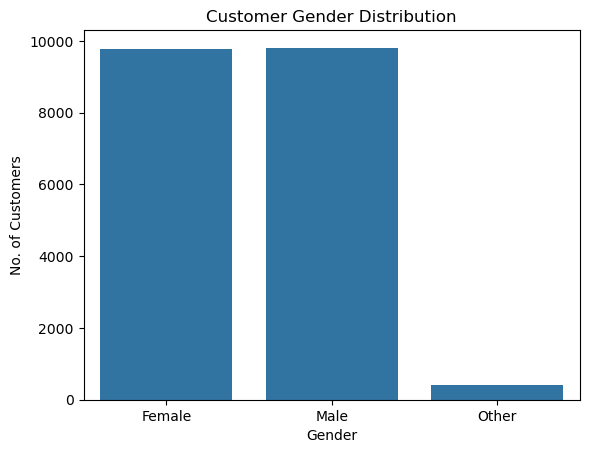

In [12]:
sns.countplot(data=customers, x="gender")
plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("No. of Customers")
plt.show()

In [13]:
customers["acquisition_channel"].value_counts()

acquisition_channel
Organic Search    5661
Paid Search       3920
Social Media      3718
Direct            3009
Email             1930
Referral          1762
Name: count, dtype: int64

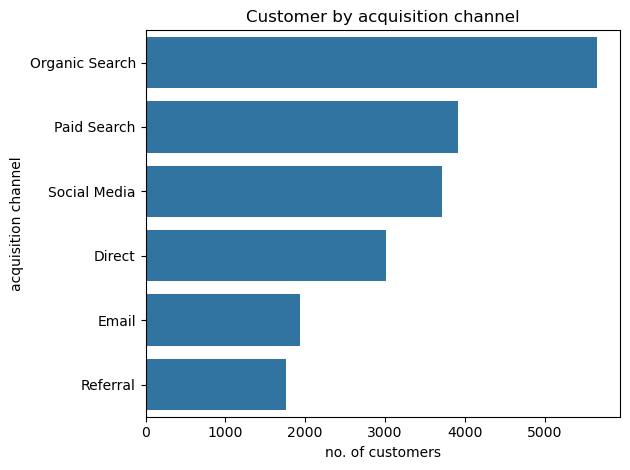

In [14]:
plt.Figure(figsize=(10,5))
sns.countplot(
    data=customers,
    y="acquisition_channel",
    order=customers["acquisition_channel"].value_counts().index
)
plt.title("Customer by acquisition channel")
plt.xlabel("no. of customers")
plt.ylabel("acquisition channel")
plt.tight_layout()
plt.show()

In [15]:
customers["signup_month"] = customers["signup_date"].dt.strftime("%Y-%m")
monthly_signups = customers.groupby("signup_month").size()
monthly_signups

signup_month
2024-01    643
2024-02    592
2024-03    605
2024-04    603
2024-05    625
2024-06    631
2024-07    614
2024-08    599
2024-09    598
2024-10    649
2024-11    603
2024-12    625
2025-01    606
2025-02    557
2025-03    647
2025-04    593
2025-05    595
2025-06    634
2025-07    632
2025-08    606
2025-09    586
2025-10    639
2025-11    562
2025-12    629
2026-01    649
2026-02    558
2026-03    598
2026-04    564
2026-05    604
2026-06    529
2026-07    650
2026-08    585
2026-09    590
dtype: int64

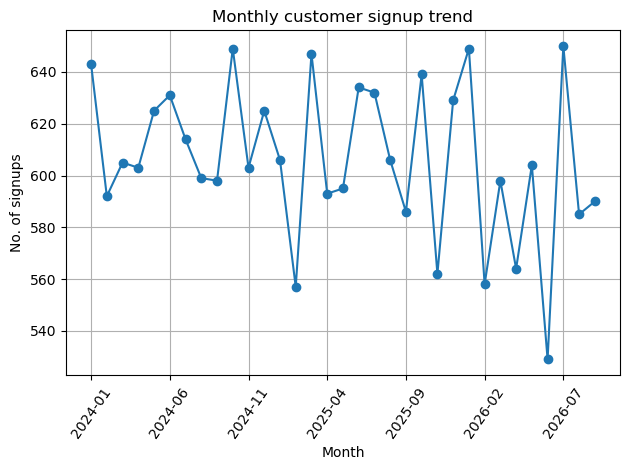

In [16]:
plt.Figure(figsize=(12,5))
monthly_signups.plot(kind='line', marker = "o")
plt.title("Monthly customer signup trend")
plt.xlabel("Month")
plt.ylabel("No. of signups")
plt.xticks(rotation = 55)
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
products = pd.read_csv("Dataset/products.csv")
products.head()

,product_id,product_name,category,brand,unit_price,unit_cost,rating
0,2001,Decor Product 001,Home & Kitchen,Vertex,858.0,611.52,4.3
1,2002,Laptop Product 002,Electronics,Aura,525.0,395.67,4.4
2,2003,Skincare Product 003,Beauty,Apex,1605.0,903.92,4.1
3,2004,Smartwatch Product 004,Electronics,PrimeOne,461.0,235.09,3.8
4,2005,Education Product 005,Books,Vertex,596.0,450.64,3.9


In [18]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    500 non-null    int64  
 1   product_name  500 non-null    str    
 2   category      500 non-null    str    
 3   brand         500 non-null    str    
 4   unit_price    500 non-null    float64
 5   unit_cost     500 non-null    float64
 6   rating        500 non-null    float64
dtypes: float64(3), int64(1), str(3)
memory usage: 27.5 KB


In [19]:
products["product_id"].duplicated().sum()

0

In [20]:
products.duplicated().sum()

0

In [21]:
products.isnull().sum()

product_id      0
product_name    0
category        0
brand           0
unit_price      0
unit_cost       0
rating          0
dtype: int64

In [22]:
products["category"].value_counts()

category
Electronics       115
Fashion           113
Home & Kitchen     82
Books              81
Sports             57
Beauty             52
Name: count, dtype: int64

In [23]:
products["unit_price"].describe()

count      500.000000
mean      1701.822000
std       1910.169377
min        150.000000
25%        646.500000
50%       1215.000000
75%       2076.250000
max      19805.000000
Name: unit_price, dtype: float64

In [24]:
products["rating"].describe()

count    500.000000
mean       4.084600
std        0.459614
min        2.700000
25%        3.800000
50%        4.100000
75%        4.400000
max        5.000000
Name: rating, dtype: float64

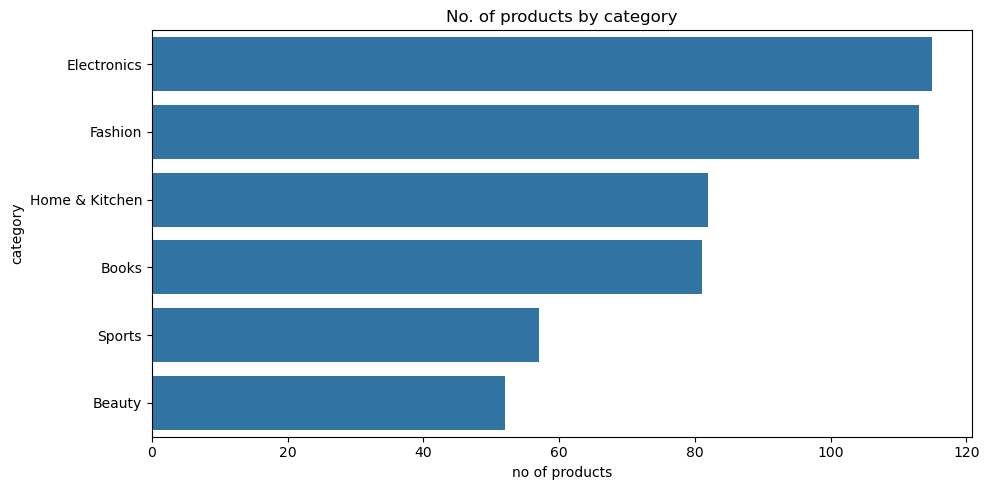

In [25]:
plt.figure(figsize=(10,5))
sns.countplot(
    data = products,
    y="category",
    order=products["category"].value_counts().index
)

plt.title("No. of products by category")
plt.xlabel("no of products")
plt.ylabel("category")
plt.tight_layout()
plt.show()

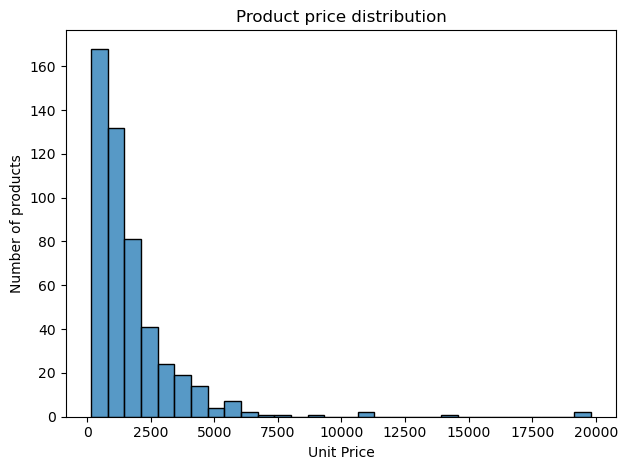

In [26]:
plt.Figure(figsize=(10,5))
sns.histplot(data=products, x="unit_price", bins=30)
plt.title("Product price distribution")
plt.xlabel("Unit Price")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()

In [27]:
products["profit_per_unit"] = (products["unit_price"] - products["unit_cost"])

products[[
    "product_name",
    "category",
    "unit_price",
    "unit_cost",
    "profit_per_unit"
]].head()

,product_name,category,unit_price,unit_cost,profit_per_unit
0,Decor Product 001,Home & Kitchen,858.0,611.52,246.48
1,Laptop Product 002,Electronics,525.0,395.67,129.33
2,Skincare Product 003,Beauty,1605.0,903.92,701.08
3,Smartwatch Product 004,Electronics,461.0,235.09,225.91
4,Education Product 005,Books,596.0,450.64,145.36


In [28]:
top_profit_products = products.sort_values(
    by="profit_per_unit",
    ascending=False
)
top_profit_products[
    ["product_name",
    "category",
    "unit_price",
    "unit_cost",
    "profit_per_unit"]
    ].head(10)

,product_name,category,unit_price,unit_cost,profit_per_unit
442,Headphones Product 443,Electronics,19805.0,11508.79,8296.21
125,T-Shirt Product 126,Fashion,14320.0,6632.66,7687.34
58,Fragrance Product 059,Beauty,19263.0,12999.36,6263.64
356,Yoga Product 357,Sports,10881.0,4930.48,5950.52
360,Skincare Product 361,Beauty,10645.0,5236.75,5408.25
318,Laptop Product 319,Electronics,9195.0,4388.81,4806.19
34,Fiction Product 035,Books,7790.0,4165.00,3625.00
50,Jacket Product 051,Fashion,5929.0,3300.81,2628.19
44,Laptop Product 045,Electronics,5792.0,3272.06,2519.94
477,Laptop Product 478,Electronics,5315.0,2838.23,2476.77


In [29]:
products["profit_margin_pct"] = (
    products["profit_per_unit"] / products["unit_price"]
) * 100

products[
    ["product_name",
    "unit_price",
    "unit_cost",
    "profit_per_unit",
    "profit_margin_pct"]
].head()

,product_name,unit_price,unit_cost,profit_per_unit,profit_margin_pct
0,Decor Product 001,858.0,611.52,246.48,28.727273
1,Laptop Product 002,525.0,395.67,129.33,24.634286
2,Skincare Product 003,1605.0,903.92,701.08,43.680997
3,Smartwatch Product 004,461.0,235.09,225.91,49.004338
4,Education Product 005,596.0,450.64,145.36,24.389262


In [30]:
top_margin_products = products.sort_values(
    by="profit_margin_pct",
    ascending=False
)
top_margin_products[
   ["product_name",
    "unit_price",
    "unit_cost",
    "profit_per_unit",
    "profit_margin_pct"]
].head(10)

,product_name,unit_price,unit_cost,profit_per_unit,profit_margin_pct
136,Cricket Product 137,281.0,126.63,154.37,54.935943
197,Fitness Product 198,3819.0,1721.17,2097.83,54.931396
428,Backpack Product 429,3585.0,1620.52,1964.48,54.797211
151,Headphones Product 152,2620.0,1184.65,1435.35,54.784351
356,Yoga Product 357,10881.0,4930.48,5950.52,54.687253
140,Sneakers Product 141,2077.0,943.05,1133.95,54.595571
465,Jacket Product 466,611.0,277.61,333.39,54.564648
52,Mixer Product 053,1742.0,794.46,947.54,54.393800
246,Backpack Product 247,977.0,445.67,531.33,54.383828
133,Sneakers Product 134,2194.0,1002.97,1191.03,54.285779


In [31]:
category_profit = products.groupby("category").agg(
    avg_price = ("unit_price", "mean"),
    avg_cost = ("unit_cost", "mean"),
    avg_profit = ("profit_per_unit", "mean"),
    avg_margin = ("profit_margin_pct", "mean")
).round(2)

category_profit.sort_values(
    by="avg_margin",
    ascending=False
)


,avg_price,avg_cost,avg_profit,avg_margin
category,,,,
Beauty,2095.40,1258.06,837.34,40.13
Electronics,1907.13,1166.44,740.69,38.79
Fashion,1542.39,931.56,610.83,37.88
Books,1659.85,1036.27,623.58,37.77
Sports,1635.74,990.01,645.73,37.49
Home & Kitchen,1471.40,938.36,533.05,37.09


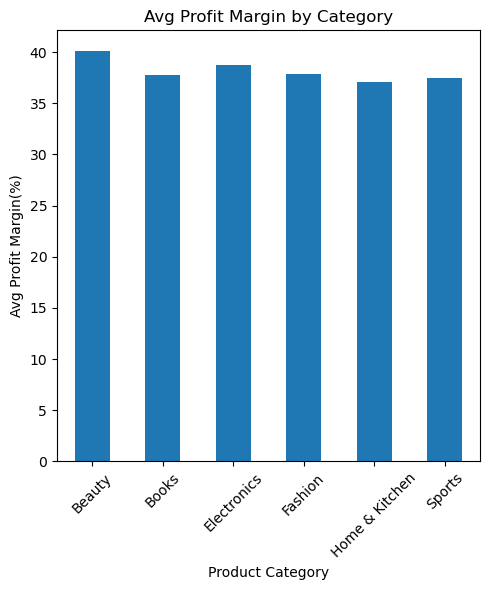

In [32]:
category_profit.sort_values(
    by="avg_margin",
    ascending=False
)
category_profit["avg_margin"].plot(
    kind="bar",
    figsize=(5,6),
)
plt.title("Avg Profit Margin by Category")
plt.xlabel("Product Category")
plt.ylabel("Avg Profit Margin(%)")
plt.xticks(rotation= 45)
plt.tight_layout()
plt.show()

In [33]:
orders = pd.read_csv("Dataset/orders.csv")
orders.head()

,order_id,customer_id,order_date,order_status,payment_method,device,sales_channel
0,517134,108355,2025-01-01 00:01:13,Delivered,Credit Card,Desktop,Organic Search
1,557069,117971,2025-01-01 00:10:12,Delivered,Net Banking,Desktop,Organic Search
2,508264,108418,2025-01-01 00:16:33,Delivered,Cash on Delivery,Desktop,Referral
3,525677,104968,2025-01-01 00:28:43,Delivered,Wallet,Mobile,Organic Search
4,513314,118048,2025-01-01 00:36:54,Delivered,Credit Card,Mobile,Direct


In [34]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   order_id        100000 non-null  int64
 1   customer_id     100000 non-null  int64
 2   order_date      100000 non-null  str  
 3   order_status    100000 non-null  str  
 4   payment_method  100000 non-null  str  
 5   device          100000 non-null  str  
 6   sales_channel   100000 non-null  str  
dtypes: int64(2), str(5)
memory usage: 5.3 MB


In [35]:
orders["order_date"] = pd.to_datetime(orders["order_date"])
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   order_id        100000 non-null  int64         
 1   customer_id     100000 non-null  int64         
 2   order_date      100000 non-null  datetime64[us]
 3   order_status    100000 non-null  str           
 4   payment_method  100000 non-null  str           
 5   device          100000 non-null  str           
 6   sales_channel   100000 non-null  str           
dtypes: datetime64[us](1), int64(2), str(4)
memory usage: 5.3 MB


In [36]:
orders.isnull().sum()

order_id          0
customer_id       0
order_date        0
order_status      0
payment_method    0
device            0
sales_channel     0
dtype: int64

In [37]:
orders.duplicated().sum()

0

In [38]:
orders["order_id"].duplicated().sum()

0

In [39]:
orders["order_status"].value_counts()

order_status
Delivered    84198
Cancelled     6889
Returned      5907
Pending       3006
Name: count, dtype: int64

In [40]:
status_pct = (
    orders["order_status"].value_counts(normalize=True) * 100
).round(2)
status_pct

order_status
Delivered    84.20
Cancelled     6.89
Returned      5.91
Pending       3.01
Name: proportion, dtype: float64

In [41]:
orders["payment_method"].value_counts()

payment_method
UPI                 32107
Credit Card         24393
Debit Card          15755
Net Banking         11968
Cash on Delivery     9908
Wallet               5869
Name: count, dtype: int64

In [42]:
payment_pct = (
    orders["payment_method"].value_counts(normalize=True) * 100
)
payment_pct

payment_method
UPI                 32.107
Credit Card         24.393
Debit Card          15.755
Net Banking         11.968
Cash on Delivery     9.908
Wallet               5.869
Name: proportion, dtype: float64

In [43]:
orders["device"].value_counts()

device
Mobile     58011
Desktop    34022
Tablet      7967
Name: count, dtype: int64

In [44]:
device_pct = (
    orders["device"].value_counts(normalize=True) * 100
)
device_pct

device
Mobile     58.011
Desktop    34.022
Tablet      7.967
Name: proportion, dtype: float64

In [45]:
orders["sales_channel"].value_counts()

sales_channel
Organic Search    26736
Paid Search       20048
Social Media      17037
Direct            16094
Email             11134
Referral           8951
Name: count, dtype: int64

In [46]:
sales_channel_pct = (
    orders["sales_channel"].value_counts(normalize=True) * 100
)
sales_channel_pct

sales_channel
Organic Search    26.736
Paid Search       20.048
Social Media      17.037
Direct            16.094
Email             11.134
Referral           8.951
Name: proportion, dtype: float64

In [47]:
orders["order_month"] = orders["order_date"].dt.strftime("%Y-%m")
monthly_orders = orders.groupby("order_month").size()
monthly_orders

order_month
2025-01    4951
2025-02    4446
2025-03    4821
2025-04    4758
2025-05    4835
2025-06    4701
2025-07    4813
2025-08    4809
2025-09    4856
2025-10    4731
2025-11    4825
2025-12    4918
2026-01    4763
2026-02    4408
2026-03    4888
2026-04    4721
2026-05    4828
2026-06    4707
2026-07    4876
2026-08    4927
2026-09    4418
dtype: int64

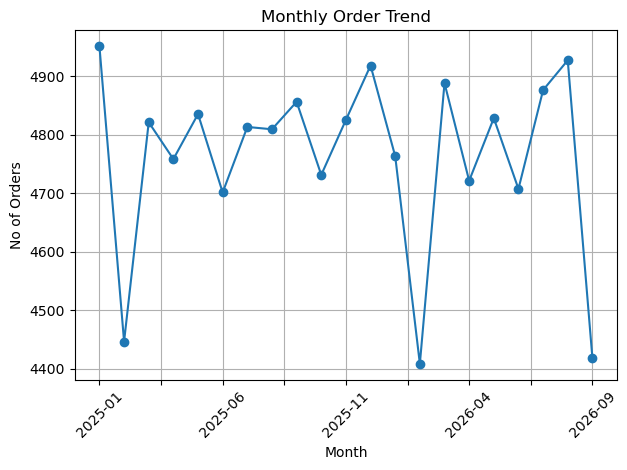

In [48]:
plt.Figure(figsize=(12,5))
monthly_orders.plot(kind="line", marker="o")
plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("No of Orders")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [49]:
pd.crosstab(orders["sales_channel"], orders["order_status"])

order_status,Cancelled,Delivered,Pending,Returned
sales_channel,,,,
Direct,1105,13566,485,938
Email,777,9326,354,677
Organic Search,1924,22483,800,1529
Paid Search,1351,16898,599,1200
Referral,612,7527,268,544
Social Media,1120,14398,500,1019


In [50]:
channel_status = pd.crosstab(
    orders["sales_channel"], orders["order_status"],
    normalize="index"
) * 100

channel_status = channel_status.round(2)
channel_status

order_status,Cancelled,Delivered,Pending,Returned
sales_channel,,,,
Direct,6.87,84.29,3.01,5.83
Email,6.98,83.76,3.18,6.08
Organic Search,7.20,84.09,2.99,5.72
Paid Search,6.74,84.29,2.99,5.99
Referral,6.84,84.09,2.99,6.08
Social Media,6.57,84.51,2.93,5.98


In [51]:
order_items = pd.read_csv("Dataset/order_items.csv")
order_items.head()

,order_id,product_id,quantity,unit_selling_price,discount_pct,revenue,profit
0,500001,2316,1,693.9,0.10,693.9,209.56
1,500002,2109,1,2166.0,0.05,2166.0,866.07
2,500002,2265,1,1757.7,0.10,1757.7,848.04
3,500002,2445,2,1292.0,0.05,2584.0,1150.54
4,500002,2118,1,150.0,0.00,150.0,47.12


In [52]:
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 197035 entries, 0 to 197034
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   order_id            197035 non-null  int64  
 1   product_id          197035 non-null  int64  
 2   quantity            197035 non-null  int64  
 3   unit_selling_price  197035 non-null  float64
 4   discount_pct        197035 non-null  float64
 5   revenue             197035 non-null  float64
 6   profit              197035 non-null  float64
dtypes: float64(4), int64(3)
memory usage: 10.5 MB


In [53]:
order_items.duplicated().sum()

36

In [54]:
order_items["order_id"].duplicated().sum()

97035

In [55]:
total_rev = order_items["revenue"].sum()
total_profit = order_items["profit"].sum()

print(total_rev.round(2))
print(total_profit.round(2))

482495073.0
165789972.42


In [56]:
total_orders = order_items["order_id"].nunique()

aov = total_rev/total_orders
print("Average Order Value:",aov.round(2))

Average Order Value: 4824.95


In [57]:
delivered_order = orders[
    orders["order_status"] == "Delivered"
]
delivered_order_ids = delivered_order["order_id"]

delivered_items = order_items[order_items["order_id"].isin(delivered_order_ids)]
delivered_rev = delivered_items["revenue"].sum()
delivered_order_count = delivered_items["order_id"].nunique()

delivered_aov = delivered_rev/delivered_order_count

print("Delivered Order Count:", delivered_order_count)
print("Delivered Order Revenue:", delivered_rev)
print("Delivered AOV:",delivered_aov)

Delivered Order Count: 84198
Delivered Order Revenue: 406672634.15000004
Delivered AOV: 4829.95598648424


In [58]:
total_profit = delivered_items["profit"].sum()
profit_margin = total_profit / delivered_rev * 100

print("Delivered Profit:", total_profit)
print("Delivered Order Revenue:", delivered_rev)
print("Profit Margin:",profit_margin)


Delivered Profit: 139690510.55999997
Delivered Order Revenue: 406672634.15000004
Profit Margin: 34.34962149640871


In [59]:
top_products = (
    delivered_items
    .groupby("product_id")
    .agg(
        total_quantity = ("quantity", "sum"),
        total_rev = ("revenue", "sum"),
        total_profit = ("profit", "sum")
    )
    .sort_values(by="total_rev", ascending=False)
    .head(10)              
)
top_products

,total_quantity,total_rev,total_profit
product_id,,,
2443,552,10242155.75,3889303.67
2059,539,9763451.55,2756796.51
2126,433,5854016.00,2982074.22
2357,532,5433971.40,2810956.04
2361,528,5254372.00,2489368.00
2319,514,4443943.50,2188095.16
2035,462,3358269.00,1434039.00
2391,510,3339014.70,558321.30
2045,569,3077579.20,1215777.06


In [60]:
top_products = top_products.reset_index()
top_products = top_products.merge(
    products[["product_id", "product_name", "category"]],
    on="product_id",
    how="left"
)

top_products[
    [
        "product_id",
        "product_name",
        "category",
        "total_quantity",
        "total_rev",
        "total_profit"
    ]
]

,product_id,product_name,category,total_quantity,total_rev,total_profit
0,2443,Headphones Product 443,Electronics,552,10242155.75,3889303.67
1,2059,Fragrance Product 059,Beauty,539,9763451.55,2756796.51
2,2126,T-Shirt Product 126,Fashion,433,5854016.00,2982074.22
3,2357,Yoga Product 357,Sports,532,5433971.40,2810956.04
4,2361,Skincare Product 361,Beauty,528,5254372.00,2489368.00
5,2319,Laptop Product 319,Electronics,514,4443943.50,2188095.16
6,2035,Fiction Product 035,Books,462,3358269.00,1434039.00
7,2391,Cookware Product 391,Home & Kitchen,510,3339014.70,558321.30
8,2045,Laptop Product 045,Electronics,569,3077579.20,1215777.06
9,2205,Fiction Product 205,Books,514,2996655.70,596486.44


In [61]:
category_performance = (
    delivered_items
    .merge(
        products[["product_id", "category"]],
        on="product_id",
        how="left"
    )
    .groupby("category")
    .agg(
        total_revenue=("revenue", "sum"),
        total_profit=("profit", "sum"),
        total_quantity=("quantity", "sum")
    )
    .sort_values(by="total_revenue", ascending=False)
)

category_performance.round(2)

,total_revenue,total_profit,total_quantity
category,,,
Electronics,1.061153e+08,36742833.74,59181
Fashion,8.179606e+07,28849220.44,57566
Books,6.386604e+07,21162965.73,41523
Home & Kitchen,5.747997e+07,18238749.49,41728
Beauty,5.211430e+07,18624601.59,26349
Sports,4.530095e+07,16072139.57,29378


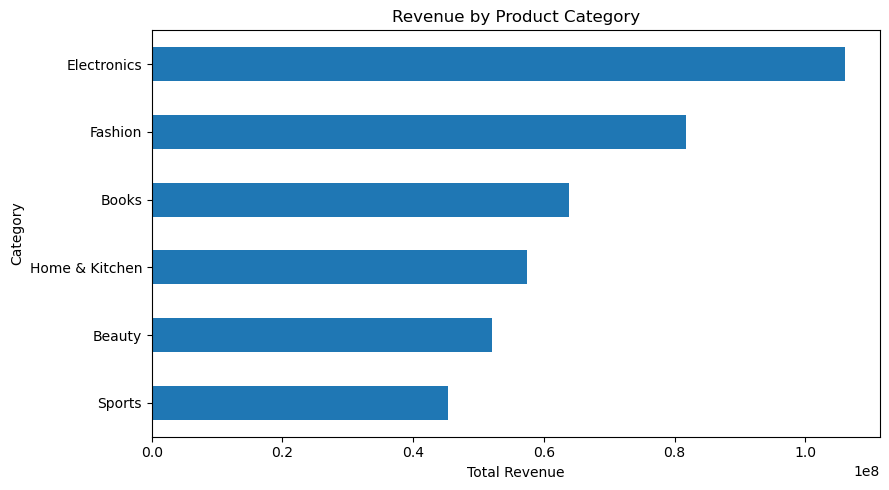

In [62]:
category_performance["total_revenue"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [63]:
delivered_customer_orders = delivered_order.groupby("customer_id").agg(
    total_orders=("order_id", "nunique")
)

delivered_customer_orders.head()

,total_orders
customer_id,
100001,6
100002,9
100003,3
100004,4
100005,1


In [64]:
repeat_customers = (
    delivered_customer_orders["total_orders"] > 1
).sum()

one_time_customers = (
    delivered_customer_orders["total_orders"] == 1
).sum()

total_customers = len(delivered_customer_orders)

repeat_percentage = repeat_customers / total_customers * 100

print("Repeat Customers:", repeat_customers)
print("One-Time Customers:", one_time_customers)
print("Total Customers:", total_customers)
print("Repeat Customer Percentage:", round(repeat_percentage, 2), "%")

Repeat Customers: 12992
One-Time Customers: 3105
Total Customers: 16097
Repeat Customer Percentage: 80.71 %


In [65]:
average_orders_per_customer = (
    delivered_customer_orders["total_orders"].mean()
)

print(
    "Average Delivered Orders per Customer:",
    round(average_orders_per_customer, 2)
)

Average Delivered Orders per Customer: 5.23


In [66]:
customer_spending = (
    delivered_items
    .merge(
        delivered_order[["order_id", "customer_id"]],
        on="order_id",
        how="left"
    )
    .groupby("customer_id")
    .agg(
        total_revenue=("revenue", "sum"),
        total_profit=("profit", "sum"),
        total_orders=("order_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
)

customer_spending.head(10)

,total_revenue,total_profit,total_orders
customer_id,,,
100096,241962.90,84721.07,37
108144,231671.90,79861.33,29
100246,227687.30,86637.97,28
105915,214891.05,67029.36,41
103038,214496.90,68744.22,36
108397,214289.95,71542.56,39
102936,212149.60,71542.81,31
101436,208709.05,61072.47,31
107541,203916.20,79293.66,35


In [67]:
customers["age_group"] = pd.cut(
    customers["age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65"]
)

age_group_counts = customers["age_group"].value_counts().sort_index()

age_group_counts

age_group
18-25    5486
26-35    8460
36-45    5023
46-55     981
56-65      50
Name: count, dtype: int64

In [68]:
channel_counts = customers["acquisition_channel"].value_counts()

channel_counts

acquisition_channel
Organic Search    5661
Paid Search       3920
Social Media      3718
Direct            3009
Email             1930
Referral          1762
Name: count, dtype: int64

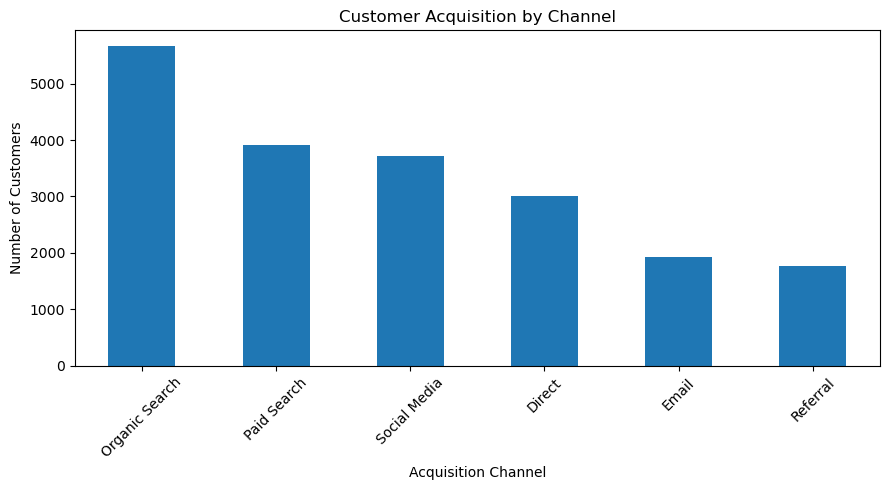

In [69]:
import matplotlib.pyplot as plt

channel_counts.plot(kind="bar", figsize=(9, 5))

plt.title("Customer Acquisition by Channel")
plt.xlabel("Acquisition Channel")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [70]:
gender_counts = customers["gender"].value_counts()

gender_counts

gender
Male      9813
Female    9782
Other      405
Name: count, dtype: int64

In [71]:
monthly_signups

signup_month
2024-01    643
2024-02    592
2024-03    605
2024-04    603
2024-05    625
2024-06    631
2024-07    614
2024-08    599
2024-09    598
2024-10    649
2024-11    603
2024-12    625
2025-01    606
2025-02    557
2025-03    647
2025-04    593
2025-05    595
2025-06    634
2025-07    632
2025-08    606
2025-09    586
2025-10    639
2025-11    562
2025-12    629
2026-01    649
2026-02    558
2026-03    598
2026-04    564
2026-05    604
2026-06    529
2026-07    650
2026-08    585
2026-09    590
dtype: int64

In [72]:
customers["signup_year"] = customers["signup_date"].dt.year

yearly_signups = customers.groupby("signup_year").size()

yearly_signups

signup_year
2024    7387
2025    7286
2026    5327
dtype: int64

In [73]:
website_sessions = pd.read_csv("Dataset/website_sessions.csv")

website_sessions.head()

,session_id,customer_id,session_date,device,traffic_source,landing_page,pages_viewed,session_duration_seconds,added_to_cart,checkout_started,purchase_completed,bounced
0,800001,114690,2026-06-14 13:40:46,Mobile,Direct,Product,1,27,0,0,0,1
1,800002,102859,2026-03-15 21:10:13,Desktop,Paid Search,Category,5,617,1,0,0,0
2,800003,106053,2026-01-14 10:07:24,Mobile,Paid Search,Category,12,266,0,0,0,0
3,800004,107738,2026-07-08 04:13:34,Desktop,Paid Search,Search,6,267,0,0,0,0
4,800005,105638,2026-09-06 02:48:02,Mobile,Direct,Home,9,756,1,0,0,0


In [74]:
website_sessions.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   session_id                150000 non-null  int64
 1   customer_id               150000 non-null  int64
 2   session_date              150000 non-null  str  
 3   device                    150000 non-null  str  
 4   traffic_source            150000 non-null  str  
 5   landing_page              150000 non-null  str  
 6   pages_viewed              150000 non-null  int64
 7   session_duration_seconds  150000 non-null  int64
 8   added_to_cart             150000 non-null  int64
 9   checkout_started          150000 non-null  int64
 10  purchase_completed        150000 non-null  int64
 11  bounced                   150000 non-null  int64
dtypes: int64(8), str(4)
memory usage: 13.7 MB


In [75]:
website_sessions.duplicated().sum()

0

In [76]:
website_sessions["session_date"] = pd.to_datetime(
    website_sessions["session_date"]
)

website_sessions["session_date"].dtype

dtype('<M8[us]')

In [77]:
device_counts = website_sessions["device"].value_counts()

device_counts

device
Mobile     90281
Desktop    49162
Tablet     10557
Name: count, dtype: int64

In [78]:
traffic_counts = website_sessions["traffic_source"].value_counts()

traffic_counts

traffic_source
Organic Search    40491
Paid Search       31274
Social Media      27033
Direct            22399
Email             15143
Referral          13660
Name: count, dtype: int64

In [79]:
landing_page_counts = website_sessions["landing_page"].value_counts()

landing_page_counts

landing_page
Product     57040
Home        29694
Category    25639
Search      22757
Campaign    14870
Name: count, dtype: int64

In [80]:
avg_session_duration = website_sessions["session_duration_seconds"].mean()

avg_session_duration

287.16422

In [81]:
avg_pages_viewed = website_sessions["pages_viewed"].mean()

avg_pages_viewed

6.001006666666667

In [82]:
bounce_rate = website_sessions["bounced"].mean() * 100

bounce_rate

1.6206666666666667

In [83]:
add_to_cart_rate = website_sessions["added_to_cart"].mean() * 100

add_to_cart_rate

19.122666666666667

In [84]:
checkout_rate = website_sessions["checkout_started"].mean() * 100

checkout_rate

11.547333333333333

In [85]:
purchase_rate = website_sessions["purchase_completed"].mean() * 100

purchase_rate

8.372666666666667

In [86]:
device_purchase_rate = (
    website_sessions.groupby("device")["purchase_completed"].mean() * 100
).round(2)

device_purchase_rate

device
Desktop    8.38
Mobile     8.38
Tablet     8.22
Name: purchase_completed, dtype: float64

In [87]:
traffic_purchase_rate = (
    website_sessions.groupby("traffic_source")["purchase_completed"].mean() * 100
).round(2)

traffic_purchase_rate.sort_values(ascending=False)

traffic_source
Social Media      8.51
Direct            8.47
Referral          8.46
Organic Search    8.41
Email             8.34
Paid Search       8.11
Name: purchase_completed, dtype: float64

In [88]:
landing_purchase_rate = (
    website_sessions.groupby("landing_page")["purchase_completed"].mean() * 100
).round(2)

landing_purchase_rate.sort_values(ascending=False)

landing_page
Product     8.45
Home        8.43
Category    8.41
Search      8.20
Campaign    8.16
Name: purchase_completed, dtype: float64

In [89]:
session_duration_by_purchase = (
    website_sessions.groupby("purchase_completed")["session_duration_seconds"]
    .mean()
)

session_duration_by_purchase

purchase_completed
0    286.885987
1    290.209093
Name: session_duration_seconds, dtype: float64

In [90]:
pages_by_purchase = (
    website_sessions.groupby("purchase_completed")["pages_viewed"]
    .mean()
)

pages_by_purchase

purchase_completed
0    5.972344
1    6.314675
Name: pages_viewed, dtype: float64

In [91]:
cart_sessions = website_sessions[
    website_sessions["added_to_cart"] == 1
]

cart_abandonment_rate = (
    (cart_sessions["purchase_completed"] == 0).mean() * 100
)

cart_abandonment_rate

56.216008924836146

In [92]:
checkout_sessions = website_sessions[
    website_sessions["checkout_started"] == 1
]

checkout_abandonment_rate = (
    (checkout_sessions["purchase_completed"] == 0).mean() * 100
)

checkout_abandonment_rate

27.492638993129724

In [93]:
duration_by_source = (
    website_sessions.groupby("traffic_source")["session_duration_seconds"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

duration_by_source

traffic_source
Organic Search    288.06
Social Media      287.72
Paid Search       287.08
Direct            286.84
Referral          285.92
Email             285.56
Name: session_duration_seconds, dtype: float64

In [94]:
website_sessions["session_month"] = (
    website_sessions["session_date"].dt.strftime("%Y-%m")
)

monthly_sessions = website_sessions.groupby("session_month").size()

monthly_sessions

session_month
2026-01    17310
2026-02    15530
2026-03    16918
2026-04    16508
2026-05    17168
2026-06    16475
2026-07    17364
2026-08    16784
2026-09    15943
dtype: int64

In [95]:
monthly_purchase_rate = (
    website_sessions.groupby("session_month")["purchase_completed"]
    .mean()
    .mul(100)
    .round(2)
)

monthly_purchase_rate

session_month
2026-01    8.37
2026-02    8.74
2026-03    8.31
2026-04    8.24
2026-05    8.42
2026-06    8.33
2026-07    8.10
2026-08    8.47
2026-09    8.42
Name: purchase_completed, dtype: float64

In [96]:
customer_activity = pd.read_csv("Dataset/customer_activity.csv")

customer_activity.head()

,activity_id,customer_id,activity_date,activity_type,device
0,900001,110841,2025-08-07 07:14:30,Login,Desktop
1,900002,109071,2025-12-21 23:11:44,Support Contact,Mobile
2,900003,114439,2025-05-19 18:35:02,Login,Desktop
3,900004,113095,2025-11-23 15:00:20,Login,Desktop
4,900005,105937,2026-07-10 17:40:32,Product View,Mobile


In [97]:
customer_activity.info()

<class 'pandas.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   activity_id    80000 non-null  int64
 1   customer_id    80000 non-null  int64
 2   activity_date  80000 non-null  str  
 3   activity_type  80000 non-null  str  
 4   device         80000 non-null  str  
dtypes: int64(2), str(3)
memory usage: 3.1 MB


In [98]:
customer_activity.duplicated().sum()

0

In [99]:
customer_activity["activity_date"] = pd.to_datetime(
    customer_activity["activity_date"]
)

customer_activity["activity_date"].dtype

dtype('<M8[us]')

In [100]:
activity_counts = customer_activity["activity_type"].value_counts()

activity_counts

activity_type
Product View       28796
Login              19842
Support Contact     8791
Add to Cart         8137
Wishlist            8038
Review              6396
Name: count, dtype: int64

In [101]:
activity_by_device = pd.crosstab(
    customer_activity["device"],
    customer_activity["activity_type"]
)

activity_by_device

activity_type,Add to Cart,Login,Product View,Review,Support Contact,Wishlist
device,,,,,,
Desktop,2876,6700,9797,2153,2903,2723
Mobile,4684,11688,16958,3805,5305,4766
Tablet,577,1454,2041,438,583,549


In [102]:
customer_activity["activity_month"] = (
    customer_activity["activity_date"].dt.strftime("%Y-%m")
)

monthly_activity = customer_activity.groupby("activity_month").size()

monthly_activity

activity_month
2025-01    3860
2025-02    3462
2025-03    3942
2025-04    3794
2025-05    3945
2025-06    3771
2025-07    3915
2025-08    3855
2025-09    3761
2025-10    3934
2025-11    3770
2025-12    3878
2026-01    3838
2026-02    3499
2026-03    3820
2026-04    3776
2026-05    3841
2026-06    3883
2026-07    3856
2026-08    3920
2026-09    3680
dtype: int64

In [103]:
monthly_activity_types = pd.crosstab(
    customer_activity["activity_month"],
    customer_activity["activity_type"]
)

monthly_activity_types

activity_type,Add to Cart,Login,Product View,Review,Support Contact,Wishlist
activity_month,,,,,,
2025-01,386,918,1425,319,434,378
2025-02,353,838,1244,298,358,371
2025-03,434,952,1415,322,418,401
2025-04,388,942,1351,282,420,411
2025-05,411,995,1403,346,428,362
2025-06,371,928,1330,325,395,422
2025-07,404,941,1433,315,424,398
2025-08,388,939,1357,304,435,432
2025-09,389,940,1371,295,417,349


In [104]:
most_active_customers = (
    customer_activity["customer_id"]
    .value_counts()
    .head(10)
)

most_active_customers

customer_id
103128    42
107094    41
100096    38
104130    37
111980    37
117904    36
105430    36
115313    35
100370    35
117457    35
Name: count, dtype: int64

In [105]:
active_customer_revenue = (
    most_active_customers.rename("activity_count")
    .reset_index()
    .merge(
        customer_spending.reset_index(),
        on="customer_id",
        how="left"
    )
    .sort_values("activity_count", ascending=False)
)

active_customer_revenue

,customer_id,activity_count,total_revenue,total_profit,total_orders
0,103128,42,146857.65,51606.61,37
1,107094,41,196541.40,71074.36,32
2,100096,38,241962.90,84721.07,37
3,104130,37,173779.25,68886.80,35
4,111980,37,185615.80,68162.45,34
5,117904,36,194776.80,69329.70,33
6,105430,36,156820.50,61243.54,28
7,115313,35,185095.65,58233.24,35
8,100370,35,88008.35,30927.44,17
9,117457,35,159135.40,52065.88,30


In [106]:
customer_activity.isnull().sum()

activity_id       0
customer_id       0
activity_date     0
activity_type     0
device            0
activity_month    0
dtype: int64

In [107]:
customer_activity_analysis = customer_activity.merge(
    customers[[
        "customer_id",
        "age",
        "gender",
        "acquisition_channel"
    ]],
    on="customer_id",
    how="left"
)

customer_activity_analysis.head()

,activity_id,customer_id,activity_date,activity_type,device,activity_month,age,gender,acquisition_channel
0,900001,110841,2025-08-07 07:14:30,Login,Desktop,2025-08,39,Female,Organic Search
1,900002,109071,2025-12-21 23:11:44,Support Contact,Mobile,2025-12,18,Male,Social Media
2,900003,114439,2025-05-19 18:35:02,Login,Desktop,2025-05,45,Female,Paid Search
3,900004,113095,2025-11-23 15:00:20,Login,Desktop,2025-11,31,Male,Organic Search
4,900005,105937,2026-07-10 17:40:32,Product View,Mobile,2026-07,33,Male,Organic Search


In [108]:
customer_activity_analysis["age_group"] = pd.cut(
    customer_activity_analysis["age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65"]
)

activity_by_age = customer_activity_analysis.groupby(
    "age_group", observed=False
).size()

print(activity_by_age)

age_group
18-25    21602
26-35    34443
36-45    19846
46-55     3935
56-65      174
dtype: int64


In [109]:
activity_by_channel = (
    customer_activity_analysis["acquisition_channel"]
    .value_counts()
)

print(activity_by_channel)

acquisition_channel
Organic Search    22738
Paid Search       16017
Social Media      15327
Direct            11481
Email              7463
Referral           6974
Name: count, dtype: int64


In [110]:
activity_counts = (
    customer_activity.groupby("customer_id")
    .size()
    .reset_index(name="activity_count")
)

activity_purchase_analysis = activity_counts.merge(
    delivered_customer_orders.reset_index(),
    on="customer_id",
    how="inner"
)

print(activity_purchase_analysis[
    ["activity_count", "total_orders"]
].corr())

                activity_count  total_orders
activity_count        1.000000      0.770232
total_orders          0.770232      1.000000


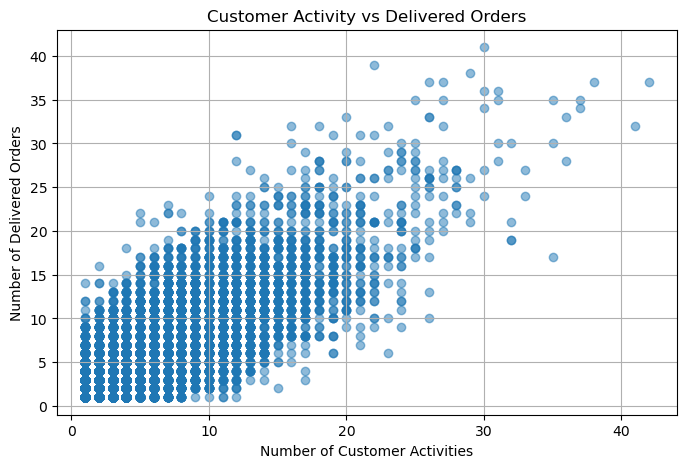

In [111]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    activity_purchase_analysis["activity_count"],
    activity_purchase_analysis["total_orders"],
    alpha=0.5
)

plt.title("Customer Activity vs Delivered Orders")
plt.xlabel("Number of Customer Activities")
plt.ylabel("Number of Delivered Orders")
plt.grid(True)
plt.show()

In [112]:
customer_revenue_channel = (
    customer_spending.reset_index()
    .merge(
        customers[["customer_id", "acquisition_channel"]],
        on="customer_id",
        how="left"
    )
)

revenue_by_channel = (
    customer_revenue_channel
    .groupby("acquisition_channel")
    .agg(
        total_revenue=("total_revenue", "sum"),
        total_profit=("total_profit", "sum"),
        customers=("customer_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
)

print(revenue_by_channel.round(2))

                     total_revenue  total_profit  customers
acquisition_channel                                        
Organic Search        1.144708e+08   39422524.35       4557
Paid Search           8.231034e+07   28133537.40       3138
Social Media          7.690972e+07   26443272.88       3028
Direct                5.921795e+07   20384009.25       2419
Email                 3.776519e+07   12992750.68       1534
Referral              3.599860e+07   12314416.00       1421


In [113]:
revenue_by_channel["revenue_per_customer"] = (
    revenue_by_channel["total_revenue"]
    / revenue_by_channel["customers"]
)

revenue_by_channel["profit_per_customer"] = (
    revenue_by_channel["total_profit"]
    / revenue_by_channel["customers"]
)

print(
    revenue_by_channel[
        ["revenue_per_customer", "profit_per_customer"]
    ].round(2).sort_values(
        "revenue_per_customer", ascending=False
    )
)

                     revenue_per_customer  profit_per_customer
acquisition_channel                                           
Paid Search                      26230.19              8965.44
Social Media                     25399.51              8732.92
Referral                         25333.28              8666.02
Organic Search                   25119.78              8650.98
Email                            24618.77              8469.85
Direct                           24480.34              8426.63


In [114]:
category_profit_analysis = (
    delivered_items
    .merge(
        products[["product_id", "category"]],
        on="product_id",
        how="left"
    )
    .groupby("category")
    .agg(
        revenue=("revenue", "sum"),
        profit=("profit", "sum"),
        units_sold=("quantity", "sum")
    )
)

category_profit_analysis["profit_margin_pct"] = (
    category_profit_analysis["profit"]
    / category_profit_analysis["revenue"]
    * 100
)

print(
    category_profit_analysis
    .sort_values("profit_margin_pct", ascending=False)
    .round(2)
)

                     revenue       profit  units_sold  profit_margin_pct
category                                                                
Beauty          5.211430e+07  18624601.59       26349              35.74
Sports          4.530095e+07  16072139.57       29378              35.48
Fashion         8.179606e+07  28849220.44       57566              35.27
Electronics     1.061153e+08  36742833.74       59181              34.63
Books           6.386604e+07  21162965.73       41523              33.14
Home & Kitchen  5.747997e+07  18238749.49       41728              31.73


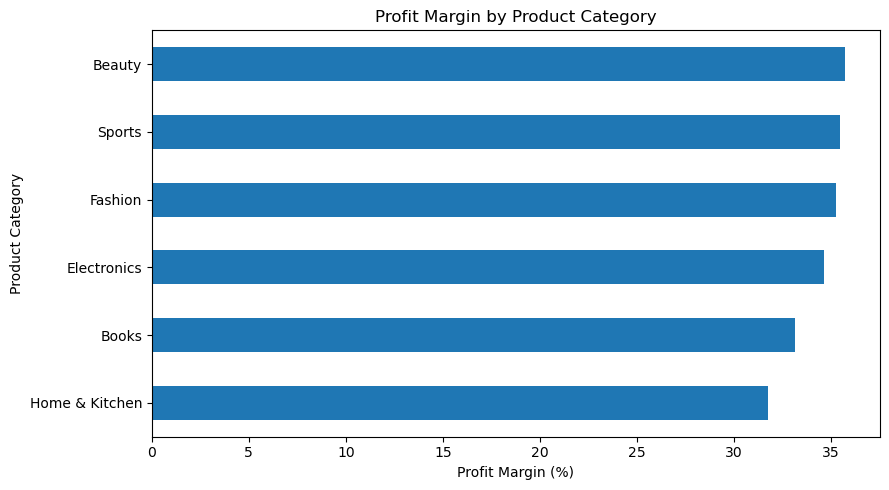

In [115]:
category_profit_analysis["profit_margin_pct"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Profit Margin by Product Category"
)

plt.xlabel("Profit Margin (%)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [116]:
repeat_purchase_analysis = (
    delivered_customer_orders
    .reset_index()
    .merge(
        customers[["customer_id", "acquisition_channel"]],
        on="customer_id",
        how="left"
    )
)

repeat_purchase_analysis["is_repeat_customer"] = (
    repeat_purchase_analysis["total_orders"] > 1
)

retention_by_channel = (
    repeat_purchase_analysis
    .groupby("acquisition_channel")
    .agg(
        total_customers=("customer_id", "nunique"),
        repeat_customers=("is_repeat_customer", "sum")
    )
)

retention_by_channel["repeat_customer_pct"] = (
    retention_by_channel["repeat_customers"]
    / retention_by_channel["total_customers"]
    * 100
)

print(
    retention_by_channel
    .sort_values("repeat_customer_pct", ascending=False)
    .round(2)
)

                     total_customers  repeat_customers  repeat_customer_pct
acquisition_channel                                                        
Referral                        1421              1174                82.62
Paid Search                     3138              2563                81.68
Social Media                    3028              2443                80.68
Direct                          2419              1944                80.36
Organic Search                  4557              3653                80.16
Email                           1534              1215                79.20


In [117]:
delivered_monthly_revenue = (
    delivered_items
    .merge(
        delivered_order[["order_id", "order_date"]],
        on="order_id",
        how="left"
    )
)

delivered_monthly_revenue["order_month"] = (
    delivered_monthly_revenue["order_date"].dt.to_period("M")
)

monthly_revenue = (
    delivered_monthly_revenue
    .groupby("order_month")["revenue"]
    .sum()
)

print(monthly_revenue.sort_values(ascending=False).head(10))

order_month
2025-01    20099994.75
2025-09    20054668.45
2025-11    19925515.20
2026-05    19912822.15
2025-03    19904737.05
2025-04    19843452.70
2025-12    19778555.05
2025-08    19694440.00
2026-07    19576905.90
2025-10    19560020.15
Freq: M, Name: revenue, dtype: float64


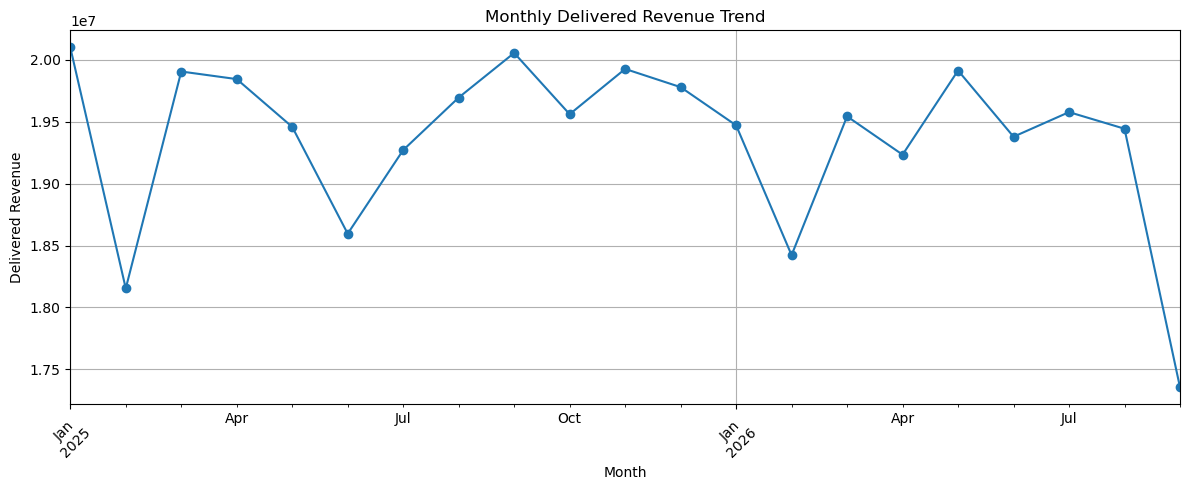

In [118]:
monthly_revenue.sort_index().plot(
    kind="line",
    figsize=(12, 5),
    marker="o",
    title="Monthly Delivered Revenue Trend"
)

plt.xlabel("Month")
plt.ylabel("Delivered Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [119]:
total_customers = customers["customer_id"].nunique()
total_orders = orders["order_id"].nunique()
delivered_order_count = delivered_order["order_id"].nunique()
total_products = products["product_id"].nunique()

total_revenue = delivered_items["revenue"].sum()
total_profit = delivered_items["profit"].sum()
overall_profit_margin = total_profit / total_revenue * 100
delivery_rate = len(delivered_order) / len(orders) * 100

print("Total Customers:", total_customers)
print("Total Orders:", total_orders)
print("Delivered Orders:", delivered_order_count)
print("Total Products:", total_products)
print("Delivered Revenue:", round(total_revenue, 2))
print("Delivered Profit:", round(total_profit, 2))
print("Profit Margin (%):", round(overall_profit_margin, 2))
print("Delivery Rate (%):", round(delivery_rate, 2))

Total Customers: 20000
Total Orders: 100000
Delivered Orders: 84198
Total Products: 500
Delivered Revenue: 406672634.15
Delivered Profit: 139690510.56
Profit Margin (%): 34.35
Delivery Rate (%): 84.2


In [120]:
customers.to_csv("customers_cleaned.csv", index=False)
products.to_csv("products_cleaned.csv", index=False)
orders.to_csv("orders_cleaned.csv", index=False)
order_items.to_csv("order_items_cleaned.csv", index=False)
website_sessions.to_csv("website_sessions_cleaned.csv", index=False)
customer_activity.to_csv("customer_activity_cleaned.csv", index=False)

print("All six datasets exported successfully!")

All six datasets exported successfully!
